# EMQA_L7_perm_dnn

**The neural network relies even more on yesterday's prices**

Energy Markets Quantitative Analysis (EMQA), Lecture 7 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L7/EMQA_L7_perm_dnn/EMQA_L7_perm_dnn.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Permutation importance of the input blocks of the tuned deep neural network (DNN): increase in the test-year MAE (EUR/MWh) when one block (prices of d-1, d-2, d-3, d-7, load, wind+solar, fundamentals, day of week) is shuffled across the test days; mean of 5 random permutations, test year 2025-11-01 to 2026-10-31, Romanian day-ahead prices. Data: test year 2025-11-01 to 2026-10-31. Source: energy-charts.info (Fraunhofer ISE); Yahoo Finance (EUA).

The numbers printed at the end are those on the slide of Lecture 7.

## Setup: chart style and helpers

In [2]:
import io
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    "figure.facecolor": "none", "axes.facecolor": "none", "savefig.transparent": True,
    "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#222222", "axes.labelcolor": "#222222", "xtick.color": "#222222", "ytick.color": "#222222",
    "text.color": "#222222", "font.size": 11, "axes.titlesize": 11.5, "axes.labelsize": 11,
    "legend.fontsize": 10.5, "legend.frameon": False, "lines.linewidth": 1.4, "font.family": "DejaVu Sans"})
PAL = {"RO": "#2a78d6", "DE_LU": "#eb6834", "HU": "#1baf7a", "BG": "#eda100",
       "c5": "#e87ba4", "c6": "#008300", "c7": "#6250d6", "c8": "#e34948"}


def legend_bottom(fig, handles=None, labels=None, ncol=4):
    """Legend centred under the axes, outside the plotting area (save_chart moves it just below the lowest axis label)."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for hh, ll in zip(*ax.get_legend_handles_labels()):
                if ll not in labels:
                    handles.append(hh)
                    labels.append(ll)
    if handles:
        fig.legend(handles, labels, loc="upper center", ncol=ncol, frameon=False, handlelength=1.6, handletextpad=0.5,
                   columnspacing=1.0, borderaxespad=0.1)


def save_chart(fig, name, bottom=None):
    """The axes use the whole figure height; the legend (if any) goes just below the lowest axis label."""
    fig.tight_layout(pad=0.3)
    if fig.legends:
        fig.canvas.draw()
        r = fig.canvas.get_renderer()
        y0 = min(ax.get_tightbbox(r).y0 for ax in fig.axes) / fig.bbox.height
        fig.legends[0].set_loc("upper center")
        fig.legends[0].set_bbox_to_anchor((0.5, y0 - 0.01), transform=fig.transFigure)
    plt.savefig(name + ".png", dpi=150, bbox_inches="tight", pad_inches=0.03, transparent=True)
    plt.show()


def show(label, value, fmt=""):
    """Print a number that appears on the slide."""
    print(f"{label}: {format(value, fmt)}")

## Data: Romanian day-ahead prices, CET delivery day x 24 hours

In [3]:
TZ = "Europe/Brussels"


def day_matrix(s):
    """UTC-indexed hourly series -> CET delivery day x 24 hours (Assignment 1 / epftoolbox DST convention) + DST flag."""
    s = s.copy()
    s.index = pd.to_datetime(s.index, utc=True).tz_convert(TZ)
    df = pd.DataFrame({"v": s.values, "day": s.index.tz_localize(None).normalize(), "h": s.index.hour})
    m = df.groupby(["day", "h"])["v"].mean().unstack("h").reindex(columns=range(24))     # 25-h day: doubled hour averaged
    days = m.index
    nh = ((((days + pd.Timedelta(days=1)).tz_localize(TZ)) - days.tz_localize(TZ)) / pd.Timedelta(hours=1)).astype(int)
    dst = pd.Series(np.asarray(nh != 24), index=days)
    for dd in days[dst.values]:
        if pd.isna(m.loc[dd, 2]):
            m.loc[dd, 2] = 0.5 * (m.loc[dd, 1] + m.loc[dd, 3])                              # 23-h day: h02 = mean(h01, h03)
    m = m.dropna(how="any")
    return m, dst.reindex(m.index)


# Romanian day-ahead price (OPCOM PZU), hourly; after 1 Oct 2025 the hour is the mean of its four quarter-hours
HP = pd.read_csv(DATA + "power_da_prices_hourly_utc.csv", usecols=["timestamp_utc", "RO"], index_col=0)
PM_ALL, DST = day_matrix(HP["RO"].dropna())          # all CET delivery days since 2015 x 24 hours
# sample of the lecture: 2022-01-01 to the cut-off 2026-10-31 (last complete month at the download of 2026-11-04)
START, END = pd.Timestamp("2022-01-01"), pd.Timestamp("2026-10-31")
CAL = pd.date_range(START, END, freq="D")
PM = PM_ALL.reindex(CAL)
assert not PM.isna().any().any(), "panel has gaps"
P_ = PM.values.astype(float)
DOW = CAL.dayofweek.values
IDX = {t: i for i, t in enumerate(CAL)}
FIRST = 7                                             # first usable target row (needs the price of d-7)
TEST0 = END - pd.Timedelta(days=364)                  # test year = the last 365 days (as in Lecture 2)
VAL0 = TEST0 - pd.Timedelta(days=365)                 # validation year = the 365 days before it
TDAYS = pd.date_range(TEST0, END, freq="D")
VDAYS = pd.date_range(VAL0, TEST0 - pd.Timedelta(days=1), freq="D")
rows_all = np.array([IDX[t] for t in TDAYS])
A = P_[rows_all]                                      # actual prices of the test year (365 days x 24 hours), EUR/MWh
print("panel", CAL[0].date(), "to", CAL[-1].date(), "| test year", TEST0.date(), "to", END.date(), A.shape)

panel 2022-01-01 to 2026-10-31 | test year 2025-11-01 to 2026-10-31 (365, 24)


## Model outputs: saved, or recomputed with `RUN_ALL = True`

The models of this chart take about 2 hours on one core (12 monthly refits x 4 seeds of the DNN, then 5 permutations x 8 blocks) to refit, more than a free Colab session allows. With `RUN_ALL = False` the notebook loads their saved outputs (`perm_dnn_results.npz`, produced by `lectures/L7/analysis_L7.py`); with `RUN_ALL = True` it recomputes them from the data with the code below, which is the code of the lecture.

In [4]:
RUN_ALL = False      # True: recompute the model outputs from the data (needs torch, xgboost, scikit-learn)

Code of the models (copied from `lectures/L7/analysis_L7.py`); defining the functions takes no time.

In [5]:
import os
import time

# constants of lectures/L7/analysis_L7.py
SEED = 20261106
PLAGS, XLAGS = (1, 2, 3, 7), (2, 3, 7)            # price lags (days) and lags of load, wind+solar (>= 2 days)
XGB_NAMES = ['P(d-1,h)', 'P(d-2,h)', 'P(d-3,h)', 'P(d-7,h)', 'P(d-1,23)', 'min P(d-1)', 'max P(d-1)', 'mean P(d-1)', 'L(d-2,h)', 'L(d-7,h)', 'RES(d-2,h)', 'RES(d-7,h)', 'mean L(d-2)', 'mean RES(d-2)', 'hydro(d-2)', 'nuclear(d-2)', 'net imports(d-2)', 'EUA(d-2)', 'hour', 'day of week']
# configurations chosen by random search on the validation year (Quantlet EMQA_L7_search)
CFG_DNN = {'n1': 512, 'n2': 0, 'act': 'softplus', 'drop': 0.1, 'lr': 0.0003, 'wd': 1e-05, 'l1': 0.0, 'batch': 64, 'load': True, 'res': True, 'fund': True, 'p3': True}
CFG_XGB = {'n_est': 1500, 'eta': 0.02, 'depth': 8, 'mcw': 5, 'sub': 0.8, 'col': 1.0, 'lam': 0.1, 'obj': 'reg:absoluteerror'}


def shift_rows(A, k):
    out = np.full_like(A, np.nan)
    out[k:] = A[:-k]
    return out


def mad_scale(x):
    x = np.asarray(x, float).ravel()
    m = np.median(x)
    s = stats.median_abs_deviation(x, scale="normal")
    return m, (s if s > 0 else 1.0)


def blocks_of(days, freq="M"):
    """(first row, last row) of each calendar month (or quarter) of a day range."""
    out = []
    for _, g in pd.Series(days, index=days).groupby(days.to_period(freq)):
        out.append((IDX[g.index[0]], IDX[g.index[-1]]))
    return out


def dnn_inputs(Pa, La, Ra, Fa, rows, sc, cfg):
    """Input vector of day d (rows): asinh-scaled prices of d-1, d-2, (d-3), d-7 (24 h each), load and wind+solar of d-2, d-3, d-7,
    the 4 daily fundamentals of d-2 and day-of-week dummies. Returns the matrix and the column range of each block."""
    m, s, mL, sL, mR, sR = sc
    cols, names = [], []
    for k in PLAGS:
        if k == 3 and not cfg["p3"]:
            continue
        cols.append(np.arcsinh((shift_rows(Pa, k)[rows] - m) / s))
        names += [f"price d-{k}"] * 24
    if cfg["load"]:
        for k in XLAGS:
            cols.append(np.arcsinh((shift_rows(La, k)[rows] - mL) / sL))
            names += ["load"] * 24
    if cfg["res"]:
        for k in XLAGS:
            cols.append(np.arcsinh((shift_rows(Ra, k)[rows] - mR) / sR))
            names += ["wind+solar"] * 24
    if cfg["fund"]:
        cols.append(Fa[rows])
        names += ["hydro", "nuclear", "net imports", "carbon"]
    cols.append(np.eye(7)[DOW[rows]])
    names += ["day of week"] * 7
    return np.column_stack(cols), np.array(names)


def _net(n_in, cfg):
    import torch.nn as nn
    act = nn.ReLU if cfg["act"] == "relu" else nn.Softplus
    layers, prev = [], n_in
    for h in [cfg["n1"]] + ([cfg["n2"]] if cfg["n2"] else []):
        layers += [nn.Linear(prev, h), act(), nn.Dropout(cfg["drop"])]
        prev = h
    layers.append(nn.Linear(prev, 24))
    return nn.Sequential(*layers)


def _train(X, Y, cfg, seed, epochs, Xv=None, yv_eur=None, m=0.0, s=1.0, patience=25):
    """Mini-batch Adam on the mean absolute error of the asinh price; L1 penalty on the input layer (Lago et al. 2021).
    With a validation block: returns the epoch with the lowest validation MAE (EUR/MWh) and the learning curves."""
    import torch
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    Xt, Yt = torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32)
    net = _net(X.shape[1], cfg)
    opt = torch.optim.Adam(net.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    first = net[0].weight
    curve_tr, curve_v, best, best_ep, since = [], [], np.inf, 1, 0
    for ep_ in range(1, epochs + 1):
        net.train()
        perm = rng.permutation(len(X))
        for b0 in range(0, len(X), cfg["batch"]):
            ix = perm[b0:b0 + cfg["batch"]]
            opt.zero_grad()
            loss = (net(Xt[ix]) - Yt[ix]).abs().mean() + cfg["l1"] * first.abs().sum() / first.numel()
            loss.backward()
            opt.step()
        if Xv is not None:
            net.eval()
            with torch.no_grad():
                ptr = m + s * np.sinh(net(Xt).numpy())
                pv = m + s * np.sinh(net(torch.tensor(Xv, dtype=torch.float32)).numpy())
            curve_tr.append(float(np.mean(np.abs(ptr - (m + s * np.sinh(Y))))))
            v = float(np.mean(np.abs(pv - yv_eur)))
            curve_v.append(v)
            if v < best - 1e-9:
                best, best_ep, since = v, ep_, 0
            else:
                since += 1
                if since >= patience:
                    break
    net.eval()
    return net, best_ep, curve_tr, curve_v


def dnn_block(Pa, La, Ra, Fa, i0, i1, cfg, seeds=(1,), max_ep=300, keep=False, lo=FIRST):
    """Fit on target rows lo..i0-1 (all before the block), forecast rows i0..i1.
    Step 1: transforms from rows up to the start of the early-stopping block; train on the first 85% of the training days,
    early-stop on the last 15% (chronological). Step 2: transforms from all training rows; refit for the chosen number of
    epochs on all training days; forecast. Seeds averaged."""
    import torch
    torch.set_num_threads(1)
    t0 = time.perf_counter()
    tr = np.arange(lo, i0)
    cut = int(len(tr) * 0.85)
    v0 = tr[cut]
    sc0 = (*mad_scale(Pa[lo:v0]), *mad_scale(La[lo:v0 - 1]), *mad_scale(Ra[lo:v0 - 1]))
    X0, _ = dnn_inputs(Pa, La, Ra, Fa, tr, sc0, cfg)
    Y0 = np.arcsinh((Pa[tr] - sc0[0]) / sc0[1])
    mu0, sg0 = X0[:cut].mean(0), X0[:cut].std(0)
    sg0[sg0 == 0] = 1
    sc = (*mad_scale(Pa[tr]), *mad_scale(La[lo:i0 - 1]), *mad_scale(Ra[lo:i0 - 1]))
    X, names = dnn_inputs(Pa, La, Ra, Fa, tr, sc, cfg)
    Y = np.arcsinh((Pa[tr] - sc[0]) / sc[1])
    mu, sg = X.mean(0), X.std(0)
    sg[sg == 0] = 1
    te = np.arange(i0, i1 + 1)
    Xte, _ = dnn_inputs(Pa, La, Ra, Fa, te, sc, cfg)
    preds, epochs, curves, models = [], [], [], []
    for sd in seeds:
        _, best_ep, ctr, cv = _train((X0[:cut] - mu0) / sg0, Y0[:cut], cfg, sd, max_ep, (X0[cut:] - mu0) / sg0,
                                     Pa[tr[cut:]], sc0[0], sc0[1])
        net, _, _, _ = _train((X - mu) / sg, Y, cfg, sd, best_ep)
        with torch.no_grad():
            preds.append(sc[0] + sc[1] * np.sinh(net(torch.tensor((Xte - mu) / sg, dtype=torch.float32)).numpy()))
        epochs.append(best_ep)
        curves.append((ctr, cv))
        if keep:
            models.append({k: v.clone() for k, v in net.state_dict().items()})
    out = {"pred": np.mean(preds, 0), "epochs": epochs, "sec": time.perf_counter() - t0, "n_seeds": len(seeds)}
    if keep:
        out.update({"models": models, "mu": mu, "sg": sg, "sc": sc, "names": names, "curves": curves})
    return out


def dnn_predict_from(state, cfg, X, mu, sg, sc):
    import torch
    torch.set_num_threads(1)
    preds = []
    for st in state:
        net = _net(X.shape[1], cfg)
        net.load_state_dict(st)
        net.eval()
        with torch.no_grad():
            preds.append(sc[0] + sc[1] * np.sinh(net(torch.tensor((X - mu) / sg, dtype=torch.float32)).numpy()))
    return np.mean(preds, 0)


QL = "EMQA_L7_perm_dnn"


def load_results(fname):
    """Saved outputs of the full computation, stored in this Quantlet folder (local copy, else the public repository)."""
    if os.path.isfile(fname):
        return dict(np.load(fname, allow_pickle=False))
    raw = urllib.request.urlopen(REPO + "Quantlets/L7/" + QL + "/" + fname).read()
    return dict(np.load(io.BytesIO(raw), allow_pickle=False))

In [6]:
if RUN_ALL:
    # ---- full information set at gate closure (12:00 CET on d-1), as in lectures/L7/analysis_L7.py
    from joblib import Parallel, delayed
    GH = pd.read_csv(DATA + "generation_ro_mw_hourly_utc.csv", index_col=0)
    LM, _ = day_matrix(GH["load"].dropna())
    RM, _ = day_matrix((GH["wind_onshore"] + GH["solar"]).dropna())
    L_, R_ = LM.reindex(CAL).values.astype(float), RM.reindex(CAL).values.astype(float)
    G = pd.read_csv(DATA + "generation_ro_mw_daily_cet.csv", parse_dates=["date_cet"]).set_index("date_cet")
    CB = pd.read_csv(DATA + "crossborder_ro_mw_daily_cet.csv", parse_dates=["date_cet"]).set_index("date_cet")
    EUA = pd.read_csv(DATA + "eua_daily.csv", parse_dates=["date"]).set_index("date")["eua_etc_co2l_eur_per_unit"]
    CAL_EX = pd.date_range(START - pd.Timedelta(days=30), END, freq="D")
    FUND_RAW = pd.DataFrame({"hydro": (G["hydro_run_of_river"] + G["hydro_water_reservoir"]).reindex(CAL_EX),
                             "nuclear": G["nuclear"].reindex(CAL_EX), "netimp": CB["sum"].reindex(CAL_EX), "eua": EUA.reindex(CAL_EX)})
    F_ = FUND_RAW.ffill().shift(2).reindex(CAL).values.astype(float)      # past only, lagged 2 days
    MB = blocks_of(TDAYS, "M")                                           # 12 monthly refits in the test year
    _vm = blocks_of(VDAYS, "M")
    VB = [(_vm[k][0], _vm[k + 2][1]) for k in range(0, 12, 3)]           # validation year: 4 quarterly refits
    FC = {}
    res_dnn = Parallel(n_jobs=-1)(delayed(dnn_block)(P_, L_, R_, F_, a, b, CFG_DNN, (1, 2, 3, 4), keep=True) for a, b in MB)
    FC["dnn"] = np.vstack([r["pred"] for r in res_dnn])                  # DNN, 4 seeds averaged, monthly refits
    A_DNN = FC["dnn"]
    BLOCKS_DNN = ["price d-1", "price d-2", "price d-3", "price d-7", "load", "wind+solar", "fund", "day of week"]
    rng = np.random.default_rng(SEED)
    perms = [rng.permutation(len(TDAYS)) for _ in range(5)]
    names0 = res_dnn[0]["names"]
    blk_cols = {b: np.where(np.isin(names0, ["hydro", "nuclear", "net imports", "carbon"] if b == "fund" else [b]))[0] for b in BLOCKS_DNN}
    blk_cols = {b: c for b, c in blk_cols.items() if len(c)}
    XM = [dnn_inputs(P_, L_, R_, F_, rows_all, r_["sc"], CFG_DNN)[0] for r_ in res_dnn]
    def perm_mae(b, pm):
        out = []
        for j, (a_, b_) in enumerate(MB):
            X = XM[j].copy()
            X[:, blk_cols[b]] = XM[j][pm][:, blk_cols[b]]
            sl = slice(a_ - MB[0][0], b_ - MB[0][0] + 1)
            out.append(dnn_predict_from(res_dnn[j]["models"], CFG_DNN, X[sl], res_dnn[j]["mu"], res_dnn[j]["sg"], res_dnn[j]["sc"]))
        return np.mean(np.abs(A - np.vstack(out)))
    _base = np.mean(np.abs(A - A_DNN))
    FC["block"] = np.array(list(blk_cols))
    FC["increase"] = np.array([np.mean([perm_mae(b, pm) for pm in perms]) - _base for b in blk_cols])
else:
    FC = load_results("perm_dnn_results.npz")
    assert list(FC.get("days", TDAYS.strftime("%Y-%m-%d"))) == list(TDAYS.strftime("%Y-%m-%d"))
print(sorted(k for k in FC if k != "days"))

['block', 'increase']


## Increase in MAE when a block is shuffled

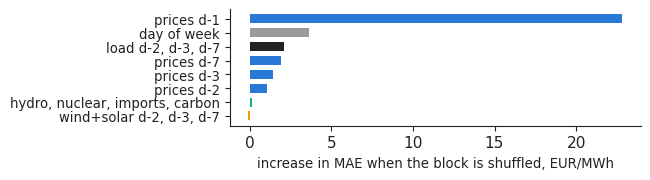

In [7]:
PI = dict(zip(FC["block"], FC["increase"]))
BNAME = {"price d-1": "prices d-1", "price d-2": "prices d-2", "price d-3": "prices d-3", "price d-7": "prices d-7",
         "load": "load d-2, d-3, d-7", "wind+solar": "wind+solar d-2, d-3, d-7", "fund": "hydro, nuclear, imports, carbon",
         "day of week": "day of week"}
fig, ax = plt.subplots(figsize=(6.4, 1.7))
bl = sorted(PI, key=PI.get)
ax.barh(range(len(bl)), [PI[b] for b in bl], height=0.65,
        color=[PAL["RO"] if b.startswith("price") else (PAL["BG"] if b == "wind+solar" else ("#222222" if b == "load" else
               (PAL["HU"] if b == "fund" else "#9a9a9a"))) for b in bl])
ax.set_yticks(range(len(bl)))
ax.set_yticklabels([BNAME[b] for b in bl], fontsize=9.5)
ax.set_xlabel("increase in MAE when the block is shuffled, EUR/MWh", fontsize=9.5)
save_chart(fig, "perm_dnn", bottom=0.02)

## Numbers on the slide

In [8]:
show('Prices d-1, EUR/MWh', PI['price d-1'], '.2f')
show('Prices d-7', PI['price d-7'], '.2f')
show('Day of week', PI['day of week'], '.2f')
show('Load', PI['load'], '.2f')
show('Wind+solar', PI['wind+solar'], '+.2f')
show('Most important block', max(PI, key=PI.get), '')

Prices d-1, EUR/MWh: 22.82
Prices d-7: 1.89
Day of week: 3.66
Load: 2.12
Wind+solar: -0.08
Most important block: price d-1
